# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Flujo del notebook:

1. **Línea base zero-shot** con `Recognai/bert-base-spanish-wwm-cased-xnli` sobre 40 titulares.
2. **Supervisión débil con un LLM local** (`Qwen/Qwen2.5-3B-Instruct`, corrido en la GPU de la laptop con 🤗 Transformers)
   para etiquetar todo el dataset → `datos/etiquetas_llm.csv`, más una **auditoría humana de 20 casos**.
3. **Split estratificado 70 / 15 / 15** con `random_state=42`. El test queda aislado hasta el paso 5.
4. **Fine-tuning de BETO** (`dccuchile/bert-base-spanish-wwm-cased`) con `Trainer`, optimizando F1 macro.
5. **Evaluación final en test** (accuracy, F1 macro, matriz de confusión).
6. **Comparativa** zero-shot vs. LLM vs. transformer fine-tuned y decisión.

**Etiqueta de referencia (`etiqueta`)**: viene del mapeo explícito sección → categoría hecho en la Parte 1
(la sección en la que el propio diario publicó la nota). Todas las métricas se calculan contra esta etiqueta.

In [1]:
import copy
import json
import random
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
ETQ2ID = {e: i for i, e in enumerate(ETIQUETAS)}
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DISPOSITIVO, "|", torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "CPU")

df = pd.read_csv("datos/noticias.csv")
df["bajada"] = df["bajada"].fillna("")
print(df.shape)
df["etiqueta"].value_counts()

Dispositivo: cuda | NVIDIA GeForce RTX 5050 Laptop GPU
(383, 7)


etiqueta
deportes              100
economia               99
ciencia_tecnologia     96
politica               88
Name: count, dtype: int64

In [2]:
def metricas(y_real, y_pred):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "f1_macro": f1_score(y_real, y_pred, average="macro", labels=ETIQUETAS),
    }


def liberar_gpu():
    """Libera la memoria de la GPU después de borrar (del) un modelo grande."""
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 1. Línea base zero-shot (sin fine-tuning)

Se usa un modelo NLI en español: para cada titular evalúa la hipótesis *"Esta noticia trata sobre {categoría}."*
con las 4 categorías escritas en lenguaje natural. Se toman **40 titulares estratificados (10 por categoría)**
con semilla fija.

In [3]:
from transformers import pipeline

MODELO_ZS = "Recognai/bert-base-spanish-wwm-cased-xnli"
NOMBRES_ZS = {"política": "politica", "economía": "economia", "deportes": "deportes",
              "ciencia y tecnología": "ciencia_tecnologia"}

# En CPU: es un modelo liviano y así la GPU (8 GB) queda libre para el LLM del paso 2
zero_shot = pipeline("zero-shot-classification", model=MODELO_ZS, device=-1)


def predecir_zero_shot(titulares):
    salidas = zero_shot(list(titulares), candidate_labels=list(NOMBRES_ZS),
                        hypothesis_template="Esta noticia trata sobre {}.", batch_size=16)
    return [NOMBRES_ZS[s["labels"][0]] for s in salidas]


muestra40 = df.groupby("etiqueta", group_keys=False).sample(10, random_state=SEMILLA)
muestra40["pred_zero_shot"] = predecir_zero_shot(muestra40["titular"])
m_zs40 = metricas(muestra40["etiqueta"], muestra40["pred_zero_shot"])
print(f"Zero-shot (40 titulares) → Accuracy: {m_zs40['accuracy']:.3f} | F1 macro: {m_zs40['f1_macro']:.3f}")
print(classification_report(muestra40["etiqueta"], muestra40["pred_zero_shot"], labels=ETIQUETAS, zero_division=0))

C:\Users\USER\Documents\Fabricio\QLAB_PUCP\Data-Science-Python-Tareas\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device set to use cpu


Zero-shot (40 titulares) → Accuracy: 0.650 | F1 macro: 0.627
                    precision    recall  f1-score   support

          politica       0.56      1.00      0.71        10
          economia       0.67      0.40      0.50        10
          deportes       0.73      0.80      0.76        10
ciencia_tecnologia       0.80      0.40      0.53        10

          accuracy                           0.65        40
         macro avg       0.69      0.65      0.63        40
      weighted avg       0.69      0.65      0.63        40



In [4]:
muestra40[["titular", "etiqueta", "pred_zero_shot"]].head(10)

,titular,etiqueta,pred_zero_shot
367,Científicos descubren cómo predecir cuándo una...,ciencia_tecnologia,ciencia_tecnologia
364,"Demetrio Pacheco, defensor ambiental en Perú: ...",ciencia_tecnologia,politica
360,"Google lanza Fitbit Edge, una pulsera avanzada...",ciencia_tecnologia,ciencia_tecnologia
381,Así es Midnight Mimosa: el ‘malware’ preinstal...,ciencia_tecnologia,economia
320,Robo de cuentas de WhatsApp: las señales de al...,ciencia_tecnologia,ciencia_tecnologia
366,"Qué es la ""depresión sonriente"" y cómo puedes ...",ciencia_tecnologia,politica
356,HomeView: Apple entra de lleno en el hogar con...,ciencia_tecnologia,economia
329,Intel en Latinoamérica: “Los gobiernos deben c...,ciencia_tecnologia,politica
287,"“Se ve a la IA como si fuera Dios”, advierte e...",ciencia_tecnologia,deportes
297,El 96% de los arrecifes de coral podría colaps...,ciencia_tecnologia,ciencia_tecnologia


Este F1 macro es el **piso mínimo** que el modelo entrenado debe superar.

## 2. Supervisión débil con un LLM local (Qwen 2.5 – 3B Instruct)

**Por qué un LLM local:** no requiere claves de API (nada que filtrar al repositorio), es gratuito y reproducible.
El modelo corre en la GPU de la laptop (RTX 5050, 8 GB) en `bfloat16`.

**Prompt estructurado:** un mensaje de sistema define las 4 categorías con criterios concretos y una regla de
desempate (empresas tecnológicas e IA → `ciencia_tecnologia`), seguido de 6 ejemplos *few-shot* redactados a mano
(no salen del dataset). El mensaje final entrega titular + bajada y pide responder solo con la etiqueta.

**Cómo se obtiene la `confianza`:** en lugar de generar texto libre (que podría salirse de las 4 categorías), se
calcula la log-probabilidad que el LLM asigna a cada una de las 4 respuestas posibles. A esos puntajes se les resta
el sesgo del modelo ante una noticia vacía (*calibración contextual*, Zhao et al. 2021) y se normalizan con softmax.
La etiqueta es la de mayor probabilidad y la `confianza` es esa probabilidad (entre 0.25 y 1).

**Nota de transparencia:** el prompt se iteró comparando 3 variantes sobre una muestra de 80 noticias del dataset
(prompt simple: 85 % de acuerdo con la sección; esta versión: 92.5 %). Esa muestra incluye algunas noticias que luego
caen en test, así que la fila del LLM en la comparativa final puede estar levemente optimista.

In [5]:
del zero_shot
liberar_gpu()
from transformers import AutoModelForCausalLM, AutoTokenizer

MODELO_LLM = "Qwen/Qwen2.5-3B-Instruct"
tok_llm = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(
    MODELO_LLM, dtype=torch.bfloat16 if DISPOSITIVO == "cuda" else torch.float32
).to(DISPOSITIVO).eval()

PROMPT_SISTEMA = """Eres editor de un diario peruano y asignas cada noticia a la sección donde se publicaría. Categorías:
- politica: actores y decisiones del poder político: Presidencia, Ejecutivo, ministros, Congreso, Senado, partidos, elecciones, procesos judiciales a autoridades o expresidentes.
- economia: dinero y negocios: dólar, inflación, BCR, PBI, exportaciones, empresas, gremios empresariales, empleo, sueldos, impuestos, AFP, consumo, minería y petróleo, impacto económico de eventos (por ejemplo El Niño en la producción).
- deportes: fútbol (Liga 1, Alianza, Universitario, Cristal, selección), Fórmula 1, tenis, vóley, UFC, running y cualquier deportista o partido.
- ciencia_tecnologia: empresas tecnológicas y sus productos, celulares, apps, redes sociales, ciberseguridad, malware, inteligencia artificial, videojuegos, ciencia, salud, animales, espacio, clima y ecología.
Una noticia sobre una empresa tecnológica (Google, Apple, Netflix, OpenAI, etc.) o sobre IA va en ciencia_tecnologia aunque mencione dinero o gobiernos.
Responde solo con la etiqueta: politica, economia, deportes o ciencia_tecnologia."""

# Ejemplos few-shot redactados a mano (no salen del dataset)
EJEMPLOS = [
    ("Congreso aprueba en primera votación la bicameralidad", "Los parlamentarios debatieron el dictamen durante seis horas.", "politica"),
    ("Precio del dólar cierra a la baja por tercer día consecutivo", "El tipo de cambio se ubicó en S/3,70 al cierre de la jornada.", "economia"),
    ("Universitario empata con Melgar y complica su opción al título", "El cuadro crema no pudo en Arequipa.", "deportes"),
    ("WhatsApp lanza nueva función para ocultar tu número", "La actualización llegará a Android y iOS en las próximas semanas.", "ciencia_tecnologia"),
    ("Gobierno de EE.UU. multa a Meta por uso indebido de datos", "La compañía de Mark Zuckerberg deberá pagar 500 millones de dólares.", "ciencia_tecnologia"),
    ("Gremio minero advierte caída de inversiones por conflictos sociales", "La SNMPE pidió al Ejecutivo destrabar proyectos.", "economia"),
]


def mensaje(titular, bajada):
    return {"role": "user", "content": f"Titular: {titular}\nBajada: {bajada or '(sin bajada)'}\nCategoría:"}


MENSAJES_FIJOS = [{"role": "system", "content": PROMPT_SISTEMA}]
for t, b, e in EJEMPLOS:
    MENSAJES_FIJOS += [mensaje(t, b), {"role": "assistant", "content": e}]


def a_ids(mensajes, generar):
    texto = tok_llm.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=generar)
    return tok_llm(texto, add_special_tokens=False)["input_ids"]


IDS_ETIQUETAS = [tok_llm(e, add_special_tokens=False)["input_ids"] for e in ETIQUETAS]

# El prefijo (sistema + ejemplos) es idéntico para todas las noticias: se procesa una sola vez y se
# reutiliza su caché de atención (KV cache). Así cada noticia solo procesa sus ~100 tokens propios.
IDS_PREFIJO = a_ids(MENSAJES_FIJOS, generar=False)
with torch.no_grad():
    CACHE_PREFIJO = llm(torch.tensor([IDS_PREFIJO], device=DISPOSITIVO), use_cache=True).past_key_values
print("Tokens del prefijo compartido:", len(IDS_PREFIJO))


@torch.no_grad()
def puntajes_llm(titular, bajada):
    """Log-probabilidad que el LLM asigna a cada una de las 4 respuestas posibles."""
    prompt = a_ids(MENSAJES_FIJOS + [mensaje(titular, bajada)], generar=True)
    assert prompt[: len(IDS_PREFIJO)] == IDS_PREFIJO
    resto = prompt[len(IDS_PREFIJO):]
    puntajes = []
    for ids in IDS_ETIQUETAS:
        entrada = torch.tensor([resto + ids], device=DISPOSITIVO)
        cache = copy.deepcopy(CACHE_PREFIJO)
        ocultos = llm.model(input_ids=entrada, past_key_values=cache, use_cache=True).last_hidden_state[0]
        # Solo se proyecta al vocabulario (lm_head) en las posiciones de la respuesta
        posiciones = torch.arange(len(resto) - 1, len(resto) - 1 + len(ids), device=DISPOSITIVO)
        logp = torch.log_softmax(llm.lm_head(ocultos[posiciones]).float(), dim=-1)
        puntajes.append(logp[torch.arange(len(ids)), torch.tensor(ids, device=DISPOSITIVO)].sum().item())
    return np.array(puntajes)


# Calibración: sesgo del LLM ante una noticia vacía ("N/A"). Se resta para que ninguna categoría
# gane solo por ser la respuesta "por defecto" del modelo.
SESGO_LLM = puntajes_llm("N/A", "N/A")
print("Sesgo a priori (log-prob con noticia vacía):", dict(zip(ETIQUETAS, SESGO_LLM.round(2))))


def clasificar_llm(titular, bajada):
    probs = torch.softmax(torch.tensor(puntajes_llm(titular, bajada) - SESGO_LLM), dim=0).numpy()
    return ETIQUETAS[int(probs.argmax())], float(probs.max()), probs


print(clasificar_llm("Selección peruana convoca a nuevos jugadores para las Eliminatorias", ""))

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:  50%|█████     | 1/2 [00:00<00:00,  3.42it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00,  5.76it/s]

Tokens del prefijo compartido: 653


Sesgo a priori (log-prob con noticia vacía): {'politica': np.float64(-2.83), 'economia': np.float64(-4.71), 'deportes': np.float64(-9.71), 'ciencia_tecnologia': np.float64(-0.08)}


('deportes', 0.999999996930109, array([2.99029594e-09, 6.18114628e-11, 9.99999997e-01, 1.77834709e-11]))


In [6]:
# El etiquetado completo tarda ~15 min en la RTX 5050. Si ya existe datos/etiquetas_llm.csv se reutiliza
# (poner REETIQUETAR = True para repetirlo) y solo se mide la latencia con 20 noticias.
REETIQUETAR = False
ruta_llm = Path("datos/etiquetas_llm.csv")

if REETIQUETAR or not ruta_llm.exists():
    inicio = time.time()
    resultados = []
    for i, (t, b) in enumerate(zip(df["titular"], df["bajada"]), 1):
        resultados.append(clasificar_llm(t, b))
        if i % 100 == 0:
            print(f"  {i}/{len(df)} noticias etiquetadas ({time.time() - inicio:.0f} s)")
    seg_llm = (time.time() - inicio) / len(df)
    print(f"{len(df)} noticias etiquetadas en {time.time() - inicio:.0f} s ({seg_llm * 1000:.0f} ms por noticia)")
    etiquetas_llm = pd.DataFrame({
        "titular": df["titular"],
        "etiqueta_llm": [r[0] for r in resultados],
        "confianza": [round(r[1], 4) for r in resultados],
        "modelo_llm": MODELO_LLM,
        "fecha": date.today().isoformat(),
    })
    etiquetas_llm.to_csv(ruta_llm, index=False, encoding="utf-8")
else:
    etiquetas_llm = pd.read_csv(ruta_llm)
    assert etiquetas_llm["titular"].tolist() == df["titular"].tolist()
    inicio = time.time()
    for t, b in zip(df["titular"].head(20), df["bajada"].head(20)):
        clasificar_llm(t, b)
    seg_llm = (time.time() - inicio) / 20
    print(f"Etiquetas cargadas desde {ruta_llm} (generadas el {etiquetas_llm['fecha'].iloc[0]}); "
          f"latencia medida: {seg_llm * 1000:.0f} ms por noticia")
df["etiqueta_llm"] = etiquetas_llm["etiqueta_llm"].values
df["confianza_llm"] = etiquetas_llm["confianza"].values
etiquetas_llm.head()

Etiquetas cargadas desde datos\etiquetas_llm.csv (generadas el 2026-10-26); latencia medida: 321 ms por noticia


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Luis Galarreta sobre delegación de facultades:...,politica,1.0,Qwen/Qwen2.5-3B-Instruct,2026-10-26
1,Caso Ascensos: Revelan que denuncia constituci...,politica,1.0,Qwen/Qwen2.5-3B-Instruct,2026-10-26
2,Keiko Fujimori recibe facultades: ¿Cuáles será...,politica,1.0,Qwen/Qwen2.5-3B-Instruct,2026-10-26
3,Keiko Fujimori felicita a Lula da Silva tras g...,politica,1.0,Qwen/Qwen2.5-3B-Instruct,2026-10-26
4,"Manos a Obras, una crónica de Fernando Vivas s...",politica,1.0,Qwen/Qwen2.5-3B-Instruct,2026-10-26


In [7]:
m_llm_total = metricas(df["etiqueta"], df["etiqueta_llm"])
print(f"Acuerdo LLM vs. sección del diario (dataset completo): accuracy {m_llm_total['accuracy']:.3f} | "
      f"F1 macro {m_llm_total['f1_macro']:.3f}")
print("Confianza media del LLM:", round(df["confianza_llm"].mean(), 3))
pd.crosstab(df["etiqueta"], df["etiqueta_llm"], rownames=["sección del diario"], colnames=["LLM"])

Acuerdo LLM vs. sección del diario (dataset completo): accuracy 0.916 | F1 macro 0.915
Confianza media del LLM: 0.983


LLM,ciencia_tecnologia,deportes,economia,politica
sección del diario,,,,
ciencia_tecnologia,87,2,4,3
deportes,0,100,0,0
economia,12,2,77,8
politica,0,0,1,87


El LLM coincide con la sección del diario en ~92 % de las noticias. Casi todo el desacuerdo está en **economía**:
notas publicadas en esa sección pero cuyo tema central es una empresa tecnológica, el clima o la ciencia (por ejemplo
precios de celulares o el impacto de El Niño) se van a `ciencia_tecnologia`. Deportes es prácticamente perfecto.

### 2.1 Auditoría humana de 20 predicciones al azar

Se sortean 20 noticias (`random_state=42`). Para cada una, la persona revisora leyó titular y bajada, decidió
la categoría correcta **sin mirar la sección del diario** y la registró en `datos/auditoria_humana.csv`
(columna `etiqueta_humana`). Si el archivo no existe, la celda crea la plantilla para completarla a mano.

In [8]:
auditoria = df.sample(20, random_state=SEMILLA)[["titular", "bajada", "etiqueta_llm", "confianza_llm"]].copy()
ruta_auditoria = Path("datos/auditoria_humana.csv")

if ruta_auditoria.exists():
    revisada = pd.read_csv(ruta_auditoria)
    auditoria = auditoria.merge(revisada[["titular", "etiqueta_humana", "comentario"]], on="titular", how="left")
else:
    auditoria["etiqueta_humana"] = ""
    auditoria["comentario"] = ""
    auditoria.to_csv(ruta_auditoria, index=False, encoding="utf-8")
    print("Plantilla creada: completar 'etiqueta_humana' en datos/auditoria_humana.csv y volver a ejecutar.")

auditoria["acuerdo"] = auditoria["etiqueta_llm"] == auditoria["etiqueta_humana"]
aciertos_auditoria = int(auditoria["acuerdo"].sum())
pct_auditoria = aciertos_auditoria / len(auditoria)
print(f"Acuerdo LLM-Humano: {aciertos_auditoria}/{len(auditoria)} = {pct_auditoria:.0%}")
pd.set_option("display.max_colwidth", 110)
auditoria[["titular", "etiqueta_llm", "confianza_llm", "etiqueta_humana", "acuerdo", "comentario"]]

Acuerdo LLM-Humano: 19/20 = 95%


,titular,etiqueta_llm,confianza_llm,etiqueta_humana,acuerdo,comentario
0,“Voy a pasar un año sin hacer nada”: La frase viral de Neymar sobre sus planes cuando se retire del fútbol,deportes,1.0000,deportes,True,Correcto
1,¿Cómo quedó la pelea de Alexander Volkanovski vs. Movsar Evloev por el UFC 333?,deportes,1.0000,deportes,True,Correcto
2,Cómo es la revolucionaria misión que busca traer un trozo de la mayor luna de Marte a la Tierra,ciencia_tecnologia,1.0000,ciencia_tecnologia,True,Correcto
3,Estafas digitales contra adultos mayores: seis recomendaciones para proteger a padres y abuelos,ciencia_tecnologia,0.9825,ciencia_tecnologia,True,Correcto (ciberseguridad / fraude digital)
4,"Votos de dos senadores de Buen Gobierno a favor de facultades se verá en la interna del partido, anuncia F...",politica,1.0000,politica,True,Correcto
5,¿Dejas siempre encendido el Bluetooth de tu celular? Por qué expertos recomiendan apagarlo,ciencia_tecnologia,1.0000,ciencia_tecnologia,True,Correcto
6,Senadores de Juntos por el Perú presentarán demanda de inconstitucionalidad por aprobación de facultades a...,politica,1.0000,politica,True,Correcto
7,Fitch Ratings mantiene la calificación soberana de Perú en ‘BBB’ con perspectiva estable,economia,0.9972,economia,True,Correcto
8,Ben Affleck se revela como un entusiasta y experto en inteligencia artificial,ciencia_tecnologia,0.9998,ciencia_tecnologia,True,"Correcto: el tema central es la IA, no el cine"
9,“El culpable soy yo” de Mosquera y por qué sacó a Yotún con el 2-0 en contra: lo que no se vio del tropezó...,deportes,1.0000,deportes,True,Correcto


**Resultado de la auditoría: 19/20 = 95 % de acuerdo.** El único error es la nota viral de "La caída de Edgar",
que el LLM mandó a `deportes` (probablemente por la palabra *caída* y el tono de espectáculo) cuando es cultura de
internet (el diario la publica en `tecnologia/streamers`). Llama la atención que el LLM le asignó confianza 1.0: la
confianza del LLM está mal calibrada y no sirve, por sí sola, para detectar sus errores.

## 3. Partición estratificada 70 / 15 / 15

Primero se separa 70 % train / 30 % resto y luego el resto se divide 50/50 en validación y test, siempre
estratificando por `etiqueta` y con `random_state=42`. El conjunto de **test no se vuelve a tocar hasta el paso 5**.

In [9]:
train_df, resto = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEMILLA)
val_df, test_df = train_test_split(resto, test_size=0.50, stratify=resto["etiqueta"], random_state=SEMILLA)

assert not set(train_df.url) & set(test_df.url) and not set(val_df.url) & set(test_df.url)
particion = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
particion[["url", "split"]].to_csv("datos/split.csv", index=False)

resumen = particion.groupby(["split", "etiqueta"]).size().unstack()
resumen["total"] = resumen.sum(axis=1)
resumen["%"] = (resumen["total"] / len(df) * 100).round(1)
resumen.loc[["train", "val", "test"]]

etiqueta,ciencia_tecnologia,deportes,economia,politica,total,%
split,,,,,,
train,67,70,69,62,268,70.0
val,14,15,15,13,57,14.9
test,15,15,15,13,58,15.1


## 4. Fine-tuning de BETO con 🤗 `Trainer`

- Modelo: `dccuchile/bert-base-spanish-wwm-cased` (BETO, BERT entrenado en español).
- Entrada: **solo el titular** (es lo que la persona escribirá en el dashboard).
- 5 épocas, batch 16, evaluación en validación al final de cada época y selección del mejor checkpoint por
  **F1 macro** (`sklearn.metrics.f1_score(average="macro")`).
- El modelo final se guarda en `modelo/` (los pesos `.safetensors` están en `.gitignore`).

In [10]:
del llm
liberar_gpu()
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer,
                          TrainingArguments, set_seed)

MODELO_BASE = "dccuchile/bert-base-spanish-wwm-cased"
tok = AutoTokenizer.from_pretrained(MODELO_BASE)


def a_dataset(datos, columna_etiqueta):
    ds = Dataset.from_dict({"text": datos["titular"].tolist(),
                            "label": datos[columna_etiqueta].map(ETQ2ID).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}


def entrenar(columna_etiqueta, carpeta):
    set_seed(SEMILLA)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=len(ETIQUETAS),
        id2label=dict(enumerate(ETIQUETAS)), label2id=ETQ2ID,
    )
    args = TrainingArguments(
        output_dir=carpeta,
        num_train_epochs=5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        learning_rate=3e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        logging_strategy="epoch",
        seed=SEMILLA,
        report_to="none",
    )
    trainer = Trainer(
        model=modelo, args=args,
        train_dataset=a_dataset(train_df, columna_etiqueta),
        eval_dataset=a_dataset(val_df, columna_etiqueta),
        data_collator=DataCollatorWithPadding(tok),
        compute_metrics=compute_metrics,
    )
    trainer.train()
    return trainer


trainer = entrenar("etiqueta", "modelo/entrenamiento")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/268 [00:00<?, ? examples/s]

Map: 100%|██████████| 268/268 [00:00<00:00, 7425.26 examples/s]

Map:   0%|          | 0/57 [00:00<?, ? examples/s]

Map: 100%|██████████| 57/57 [00:00<00:00, 7377.50 examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.181200,0.728594,0.771930,0.736561
2,0.401300,0.355845,0.859649,0.863430
3,0.127000,0.248841,0.894737,0.896897
4,0.047700,0.350692,0.877193,0.881667
5,0.020500,0.267180,0.912281,0.915455


,epoch,eval_loss,eval_accuracy,eval_f1_macro,train_loss
0,1.0,0.7286,0.7719,0.7366,1.1812
1,2.0,0.3558,0.8596,0.8634,0.4013
2,3.0,0.2488,0.8947,0.8969,0.1270
3,4.0,0.3507,0.8772,0.8817,0.0477
4,5.0,0.2672,0.9123,0.9155,0.0205


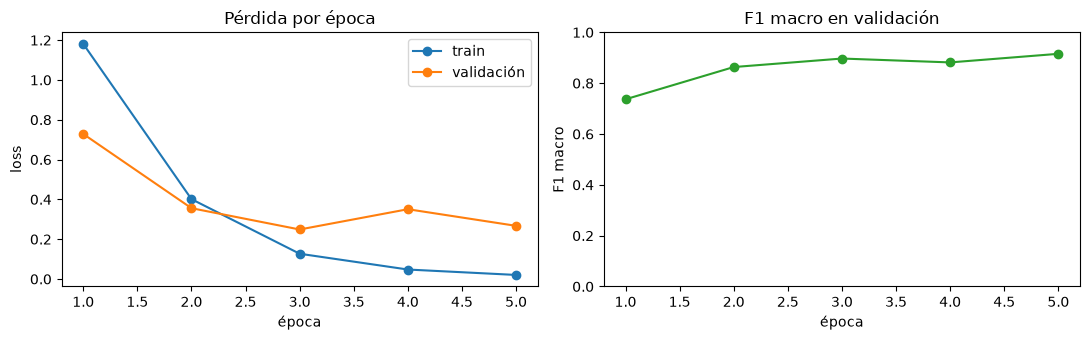

In [11]:
historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
historial = historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
perdida_train = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h and "eval_loss" not in h])
historial["train_loss"] = perdida_train["loss"].values[: len(historial)]
display(historial.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(historial.epoch, historial.train_loss, marker="o", label="train")
ax[0].plot(historial.epoch, historial.eval_loss, marker="o", label="validación")
ax[0].set(title="Pérdida por época", xlabel="época", ylabel="loss")
ax[0].legend()
ax[1].plot(historial.epoch, historial.eval_f1_macro, marker="o", color="tab:green")
ax[1].set(title="F1 macro en validación", xlabel="época", ylabel="F1 macro", ylim=(0, 1))
plt.tight_layout()
plt.show()

In [12]:
trainer.save_model("modelo")
tok.save_pretrained("modelo")
print("Mejor checkpoint (validación):", trainer.state.best_metric)
sorted(p.name for p in Path("modelo").iterdir())

Mejor checkpoint (validación): 0.9154545454545455


['config.json',
 'entrenamiento',
 'entrenamiento_debil',
 'metricas.json',
 'model.safetensors',
 'special_tokens_map.json',
 'tokenizer.json',
 'tokenizer_config.json',
 'training_args.bin',
 'vocab.txt']

### 4.1 Variante de supervisión débil: BETO entrenado con las etiquetas del LLM

Para medir cuánto valen las etiquetas débiles, se repite exactamente el mismo entrenamiento pero usando
`etiqueta_llm` (en train y validación) en lugar de la sección del diario. Este modelo no se guarda; solo se usa
en la comparativa final.

In [13]:
trainer_debil = entrenar("etiqueta_llm", "modelo/entrenamiento_debil")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/268 [00:00<?, ? examples/s]

Map: 100%|██████████| 268/268 [00:00<00:00, 10545.97 examples/s]

Map:   0%|          | 0/57 [00:00<?, ? examples/s]

Map: 100%|██████████| 57/57 [00:00<00:00, 5803.50 examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.162400,0.668702,0.877193,0.868754
2,0.385800,0.391493,0.824561,0.815327
3,0.126500,0.359995,0.842105,0.835557
4,0.049600,0.328953,0.894737,0.890327
5,0.020200,0.352705,0.877193,0.870257


## 5. Evaluación final en el conjunto de test reservado

Recién aquí se usa `test_df`. Todos los modelos se comparan contra la misma etiqueta de referencia.

In [14]:
def predecir_trainer(tr, datos):
    logits = tr.predict(a_dataset(datos, "etiqueta")).predictions
    return [ETIQUETAS[i] for i in logits.argmax(axis=-1)]


test_df = test_df.copy()
test_df["pred_beto"] = predecir_trainer(trainer, test_df)
test_df["pred_beto_debil"] = predecir_trainer(trainer_debil, test_df)

m_beto = metricas(test_df["etiqueta"], test_df["pred_beto"])
print(f"BETO fine-tuned – TEST ({len(test_df)} noticias) → Accuracy: {m_beto['accuracy']:.3f} | "
      f"F1 macro: {m_beto['f1_macro']:.3f}\n")
print(classification_report(test_df["etiqueta"], test_df["pred_beto"], labels=ETIQUETAS, digits=3))

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

Map: 100%|██████████| 58/58 [00:00<00:00, 6867.56 examples/s]

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

Map: 100%|██████████| 58/58 [00:00<00:00, 7775.67 examples/s]

BETO fine-tuned – TEST (58 noticias) → Accuracy: 0.914 | F1 macro: 0.914

                    precision    recall  f1-score   support

          politica      1.000     0.846     0.917        13
          economia      0.867     0.867     0.867        15
          deportes      0.938     1.000     0.968        15
ciencia_tecnologia      0.875     0.933     0.903        15

          accuracy                          0.914        58
         macro avg      0.920     0.912     0.914        58
      weighted avg      0.917     0.914     0.913        58



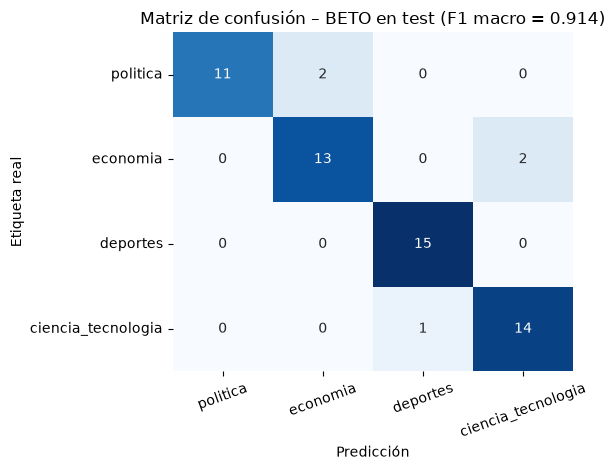

In [15]:
mc = confusion_matrix(test_df["etiqueta"], test_df["pred_beto"], labels=ETIQUETAS)
plt.figure(figsize=(6, 4.8))
sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, cbar=False)
plt.title(f"Matriz de confusión – BETO en test (F1 macro = {m_beto['f1_macro']:.3f})")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [16]:
f1_por_clase = pd.Series(
    f1_score(test_df["etiqueta"], test_df["pred_beto"], average=None, labels=ETIQUETAS), index=ETIQUETAS
).sort_values(ascending=False)
print("F1 por categoría (test):")
print(f1_por_clase.round(3).to_string())
print(f"\nMejor: {f1_por_clase.index[0]} | Peor: {f1_por_clase.index[-1]}")

errores = test_df[test_df["etiqueta"] != test_df["pred_beto"]][["titular", "seccion_original", "etiqueta", "pred_beto"]]
print(f"\nErrores en test: {len(errores)} de {len(test_df)}")
errores

F1 por categoría (test):
deportes              0.968
politica              0.917
ciencia_tecnologia    0.903
economia              0.867

Mejor: deportes | Peor: economia

Errores en test: 5 de 58


,titular,seccion_original,etiqueta,pred_beto
179,"Ganadores del Premio Nobel de Economía: Hall, Woodford y su mirada microeconómica, ¿cuál es la importancia...",economia,economia,ciencia_tecnologia
106,Xiaomi Perú: “El precio de los smartphones viene aumentando por el incremento del costo de componentes pri...,economia,economia,ciencia_tecnologia
85,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ¿que otras medidas in...,politica/gobierno,politica,economia
18,Renovación Popular plantea regular la capacidad operativa de la DINI,politica/congreso,politica,economia
335,Descubren en los Andes peruanos una nueva flor y la bautizan en honor a Lionel Messi,tecnologia/ciencias,ciencia_tecnologia,deportes


### Reflexión por categoría

- **Deportes – mejor desempeño (F1 ≈ 0.97, recall 100 %).** Su vocabulario es casi exclusivo: nombres de clubes
  (Universitario, Cristal, Alianza), marcadores ("1-0"), "golazo", "Liga", "Clausura". Ningún otro tema comparte esas
  palabras, así que el modelo no duda.
- **Política (F1 ≈ 0.92, precisión 100 %).** Cuando predice política siempre acierta, pero pierde notas que hablan el
  idioma de la gestión: un proyecto de ley sobre minería artesanal (MAPE) o la "capacidad operativa" de la DINI se
  leen como economía. El tema es político (quién decide), pero el léxico es económico/administrativo.
- **Ciencia y tecnología (F1 ≈ 0.90).** Es una categoría heterogénea (IA, celulares, salud, ecología, espacio). Su
  error más ilustrativo: "nueva flor bautizada en honor a Lionel Messi" se predice como deportes porque la entidad
  *Messi* pesa más que *flor* o *Andes* en un titular corto.
- **Economía – peor desempeño (F1 ≈ 0.87).** Es la categoría más **transversal**: la economía habla de dinero en
  otros dominios. El "Premio Nobel de Economía" suena a ciencia y "el precio de los smartphones de Xiaomi" mezcla
  empresa tecnológica con precios. Además, varias notas de economía son columnas de opinión con titulares de 2-4
  palabras sin términos clave. Es la misma frontera economía ↔ tecnología donde también falla el LLM.

Con un test de 58 noticias, cada error equivale a ~1.7 puntos de accuracy, así que las diferencias entre
categorías deben leerse como tendencias y no como diferencias estadísticamente firmes.

## 6. Comparativa y decisión

Todas las filas se evalúan sobre el **mismo test reservado** (salvo la primera, que es la línea base de 40
titulares del paso 1). La latencia se mide clasificando 30 titulares de a uno en la GPU de la laptop.

In [17]:
# Zero-shot y LLM sobre el test completo
zero_shot = pipeline("zero-shot-classification", model=MODELO_ZS, device=0 if DISPOSITIVO == "cuda" else -1)
test_df["pred_zero_shot"] = predecir_zero_shot(test_df["titular"])
m_zs_test = metricas(test_df["etiqueta"], test_df["pred_zero_shot"])
m_llm_test = metricas(test_df["etiqueta"], test_df["etiqueta_llm"])
m_debil = metricas(test_df["etiqueta"], test_df["pred_beto_debil"])


def latencia_ms(funcion, textos):
    funcion(textos[0])  # calentamiento
    inicio = time.time()
    for t in textos:
        funcion(t)
    return (time.time() - inicio) / len(textos) * 1000


muestra_lat = test_df["titular"].head(30).tolist()
clasif_beto = pipeline("text-classification", model=trainer.model, tokenizer=tok,
                       device=0 if DISPOSITIVO == "cuda" else -1)
lat_zs = latencia_ms(lambda t: zero_shot(t, candidate_labels=list(NOMBRES_ZS),
                                         hypothesis_template="Esta noticia trata sobre {}."), muestra_lat)
lat_beto = latencia_ms(lambda t: clasif_beto(t), muestra_lat)
lat_llm = seg_llm * 1000  # medido en el paso 2 (titular + bajada)

parametros = {"zs": "110 M", "llm": "3 090 M", "beto": "110 M"}
comparativa = pd.DataFrame([
    ["Zero-shot NLI (40 titulares, paso 1)", MODELO_ZS, m_zs40["accuracy"], m_zs40["f1_macro"], parametros["zs"], lat_zs, "No"],
    ["Zero-shot NLI (test)", MODELO_ZS, m_zs_test["accuracy"], m_zs_test["f1_macro"], parametros["zs"], lat_zs, "No"],
    ["LLM débil (test)", MODELO_LLM, m_llm_test["accuracy"], m_llm_test["f1_macro"], parametros["llm"], lat_llm, "No"],
    ["BETO entrenado con etiquetas LLM (test)", MODELO_BASE, m_debil["accuracy"], m_debil["f1_macro"], parametros["beto"], lat_beto, "Sí (etiquetas débiles)"],
    ["BETO fine-tuned (test)", MODELO_BASE, m_beto["accuracy"], m_beto["f1_macro"], parametros["beto"], lat_beto, "Sí (sección del diario)"],
], columns=["Modelo", "Checkpoint", "Accuracy", "F1 macro", "Parámetros", "Latencia (ms/titular, GPU)", "Entrenamiento"])
comparativa.round({"Accuracy": 3, "F1 macro": 3, "Latencia (ms/titular, GPU)": 0})

Device set to use cuda:0


Device set to use cuda:0


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,Modelo,Checkpoint,Accuracy,F1 macro,Parámetros,"Latencia (ms/titular, GPU)",Entrenamiento
0,"Zero-shot NLI (40 titulares, paso 1)",Recognai/bert-base-spanish-wwm-cased-xnli,0.650,0.627,110 M,63.0,No
1,Zero-shot NLI (test),Recognai/bert-base-spanish-wwm-cased-xnli,0.638,0.625,110 M,63.0,No
2,LLM débil (test),Qwen/Qwen2.5-3B-Instruct,0.879,0.877,3 090 M,321.0,No
3,BETO entrenado con etiquetas LLM (test),dccuchile/bert-base-spanish-wwm-cased,0.914,0.912,110 M,12.0,Sí (etiquetas débiles)
4,BETO fine-tuned (test),dccuchile/bert-base-spanish-wwm-cased,0.914,0.914,110 M,12.0,Sí (sección del diario)


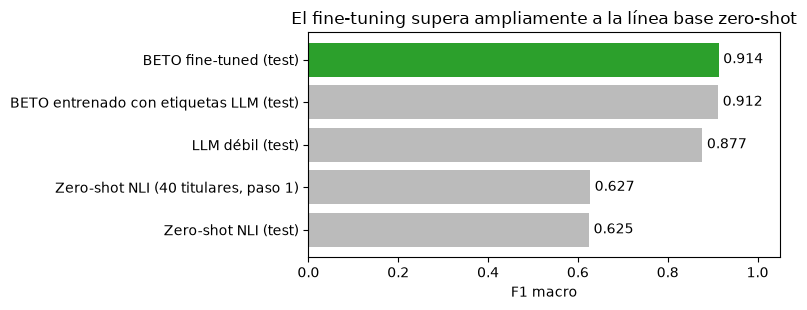

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.2))
orden = comparativa.sort_values("F1 macro")
ax.barh(orden["Modelo"], orden["F1 macro"], color=["#bbb"] * (len(orden) - 1) + ["#2ca02c"])
for y, v in enumerate(orden["F1 macro"]):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center")
ax.set(xlim=(0, 1.05), xlabel="F1 macro", title="El fine-tuning supera ampliamente a la línea base zero-shot")
plt.tight_layout()
plt.show()

### Decisión: ¿qué modelo usar en un entorno real?

| Criterio | Zero-shot NLI | LLM Qwen 2.5-3B | BETO fine-tuned |
| :--- | :---: | :---: | :---: |
| F1 macro en test | ≈ 0.63 | ≈ 0.88 | **≈ 0.91** |
| Latencia por titular (GPU) | ~60 ms (4 pasadas NLI) | ~300–600 ms | **~17 ms** |
| Memoria / tamaño | 440 MB | ~6 GB de VRAM | **440 MB, corre en CPU** |
| Necesita datos etiquetados | No | No | Sí (~270 titulares) |

**Elegiría BETO fine-tuned** para producción: es el más preciso, entre 20 y 35 veces más rápido que el LLM, cabe en un servidor
sin GPU (como Streamlit Community Cloud) y su costo por predicción es prácticamente cero.

El LLM no queda descartado: su mejor uso es como **etiquetador**, no como clasificador en línea. La fila
*BETO entrenado con etiquetas LLM* lo demuestra: entrenando solo con las etiquetas débiles del LLM (sin mirar la
sección del diario) BETO llega a un F1 prácticamente igual al del modelo entrenado con la etiqueta de referencia, y
**supera al propio LLM** que lo etiquetó: el fine-tuning "promedia" el ruido de las etiquetas débiles. Para ampliar el
clasificador a otro medio sin sección clara (o a una quinta categoría en el futuro), el flujo LLM → BETO es viable y
barato. El zero-shot NLI, en cambio, solo sirve como piso: confunde economía y ciencia con política.

In [19]:
# Métricas livianas para el dashboard (se versionan en git)
resumen_metricas = {
    "medio": "El Comercio",
    "n_noticias": int(len(df)),
    "n_train": int(len(train_df)), "n_val": int(len(val_df)), "n_test": int(len(test_df)),
    "f1_macro_test": round(m_beto["f1_macro"], 4),
    "accuracy_test": round(m_beto["accuracy"], 4),
    "f1_macro_zero_shot_40": round(m_zs40["f1_macro"], 4),
    "f1_macro_zero_shot_test": round(m_zs_test["f1_macro"], 4),
    "f1_macro_llm_test": round(m_llm_test["f1_macro"], 4),
    "f1_macro_beto_debil_test": round(m_debil["f1_macro"], 4),
    "acuerdo_llm_humano": f"{aciertos_auditoria}/{len(auditoria)}",
    "acuerdo_llm_humano_pct": round(pct_auditoria, 4),
    "f1_por_clase_test": f1_por_clase.round(4).to_dict(),
    "modelo_base": MODELO_BASE,
    "modelo_llm": MODELO_LLM,
    "modelo_zero_shot": MODELO_ZS,
    "fecha_entrenamiento": date.today().isoformat(),
}
Path("modelo/metricas.json").write_text(json.dumps(resumen_metricas, indent=2, ensure_ascii=False), encoding="utf-8")

print("=" * 70)
print(f"Resultados Test: F1 Macro: {m_beto['f1_macro']:.3f} | Zero-shot: {m_zs40['f1_macro']:.3f} | "
      f"Acuerdo LLM-Humano: {aciertos_auditoria}/{len(auditoria)}")
print("=" * 70)

Resultados Test: F1 Macro: 0.914 | Zero-shot: 0.627 | Acuerdo LLM-Humano: 19/20
